# V-JEPA 2.1: dense features from video

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/vision/vjepa21.ipynb)

[V-JEPA 2.1](https://arxiv.org/abs/2603.14482) ([code](https://github.com/facebookresearch/vjepa2)) keeps the [V-JEPA 2](vjepa.ipynb) recipe, predicting EMA features of masked tubes, and makes every patch token useful on its own. Two changes do it:
- a **context loss**: the predictor also reproduces the target at the visible tokens, weighted by $1/\sqrt{d}$ in their distance $d$ to the nearest masked one;
- **deep self-supervision**: the predictor reads and predicts four levels of the encoder, not only the last.

Here both models train side by side on the same street clips and masks, and we compare their tokens.

In [ ]:
import importlib.util
import os
import urllib.request

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"
    os.makedirs("assets", exist_ok=True)
    for name in ["street.mp4"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/latent-horizon/pytorch-world/main/examples/vision/assets/{name}", f"assets/{name}")

In [2]:
import torch
import torch.nn.functional as F

from torch_world import metrics, plots
from torch_world.datasets import random_clips, read_video
from torch_world.masks import MultiBlock3DMask
from torch_world.models import VJEPA, VJEPA21, VJEPA21Encoder, VJEPA21Predictor
from torch_world.nn import MaskedPredictor, VisionTransformer
from torch_world.utils import linear_schedule

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
FRAMES, STEPS = 8, 3000

## The street
A London street filmed from a fixed camera, with buses and cabs driving through. A clip is a fixed 96 px window of it, 8 frames long, every second frame of the footage, as the camera saw it: the street stays put and the traffic moves.

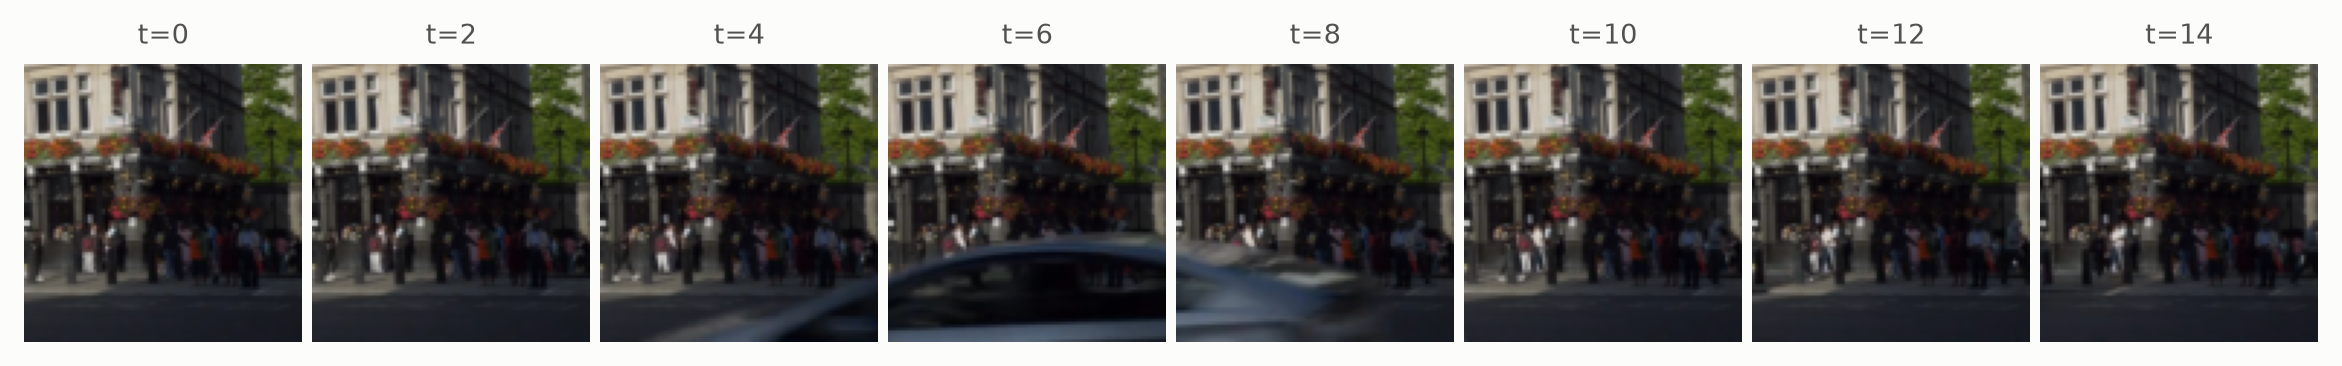

In [3]:
street = read_video("assets/street.mp4", size=(216, 384), device=device)


def clips(n, generator=None):
    return random_clips(street, n, length=FRAMES, size=96, stride=2, generator=generator)


plots.images(clips(1, torch.Generator().manual_seed(1))[0].transpose(0, 1).cpu(), [f"t={2 * t}" for t in range(FRAMES)])

## Tube masks
A tube masks the same region in every frame, so the model cannot copy a hidden patch from a neighbouring frame. Two strategies run together, as in V-JEPA 2: many small short-range tubes and a few large long-range ones. Each strategy hides its tubes from the encoder, and the predictor fills them in.

In [4]:
vit = dict(img_size=96, patch_size=8, embed_dim=192, depth=6, num_heads=6, num_frames=FRAMES, use_rope=True)
grid = (FRAMES // 2, 12, 12)  # tubelets of 2 frames, 12 x 12 patches
maskers = [
    MultiBlock3DMask(grid, spatial_scale=(0.15, 0.15), num_blocks=8),
    MultiBlock3DMask(grid, spatial_scale=(0.7, 0.7), num_blocks=2),
]


def masks(n):
    pairs = [masker(n) for masker in maskers]
    return [enc.to(device) for (enc,), _ in pairs], [pred.to(device) for _, (pred,) in pairs]

## Two models of the same size
The same 6-block ViT and 4-block predictor. V-JEPA 2.1's predictor also reads blocks 0, 2 and 3 of the encoder and has a second head for the visible tokens.

In [5]:
head = dict(predictor_dim=96, depth=4, num_heads=6, num_mask_tokens=2, zero_init_mask_tokens=True, use_rope=True)
models = {
    "V-JEPA 2": VJEPA(VisionTransformer(**vit), MaskedPredictor(grid, 192, **head)).to(device),
    "V-JEPA 2.1": VJEPA21(VJEPA21Encoder(**vit), VJEPA21Predictor(grid, 192, **head)).to(device),
}

## Train
Both models see the same clips and masks. As in the paper, the context loss weight warms up from 0 to 0.5, here between 10% and 20% of training.

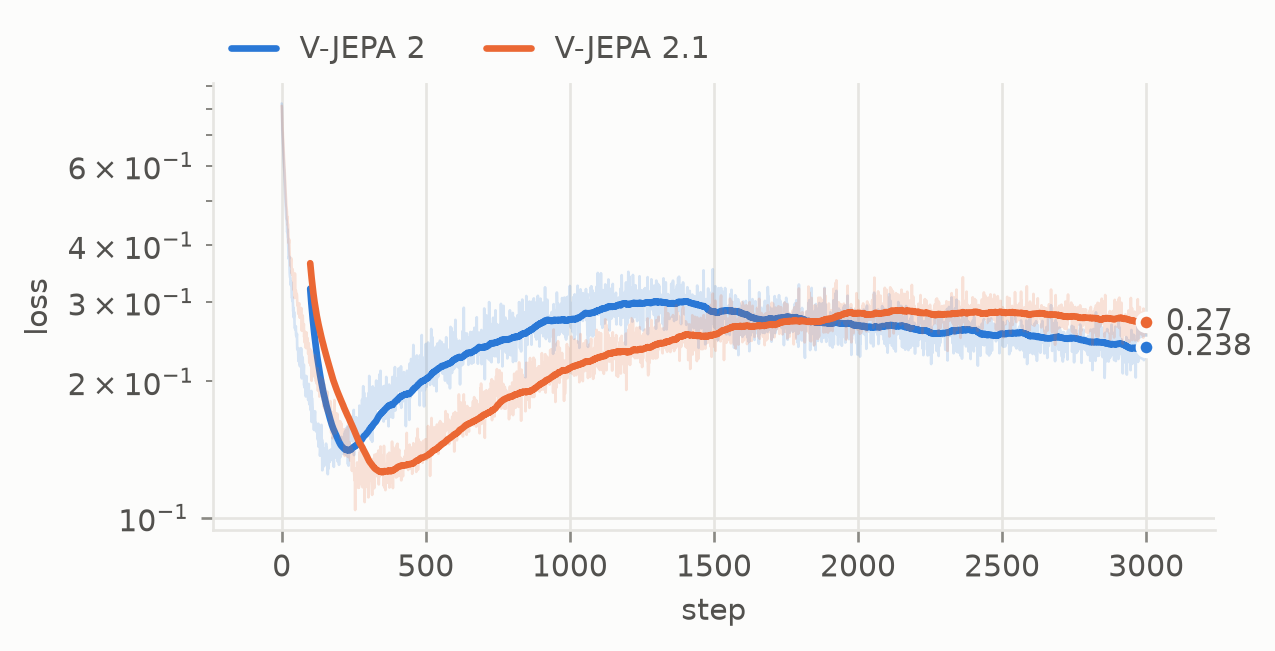

In [6]:
opts = {name: torch.optim.AdamW(m.parameters(), lr=5e-4, weight_decay=0.04) for name, m in models.items()}
log = {"V-JEPA 2": [], "V-JEPA 2.1": []}
for step in range(STEPS):
    batch, (masks_enc, masks_pred) = clips(32), masks(32)
    context = linear_schedule(0.0, 0.5, max(0, step - STEPS // 10), STEPS // 10)
    for name, model in models.items():
        extra = {"context_coeff": context} if name == "V-JEPA 2.1" else {}
        out = model(batch, masks_enc, masks_pred, **extra)
        opts[name].zero_grad()
        out["loss"].backward()
        opts[name].step()
        model.update_target(linear_schedule(0.998, 1.0, step, STEPS))
        log[name].append(out["loss"].item())
plots.curves(log, smooth=100)

## What the features know
Frozen target encoders on 2048 fresh clips (1536 to fit, 512 to test), against the same ViT at random initialization:
- **attentive probe**, V-JEPA's evaluation: a learned query cross-attends to all tokens and classifies how busy the clip is (still, some traffic, a lot: terciles of how much its pixels change; chance is 33%);
- **dense probe**: from each token alone, a linear map regresses how much its own patch changes over its 2 frames, scored by R². This asks every token to know where things move;
- **RankMe**: the effective rank of the tokens, out of 192 dimensions, after removing their mean.

In [7]:
test = clips(2048, torch.Generator().manual_seed(7))
change = (test[:, :, 1:] - test[:, :, :-1]).abs().mean(1)  # (N, 7, 96, 96)
motion = F.avg_pool3d(torch.cat([change, change[:, -1:]], 1)[:, None], (2, 8, 8)).flatten(1)  # (N, 576), one per token
busy = torch.bucketize(motion.mean(1), motion.mean(1).quantile(torch.tensor([1 / 3, 2 / 3], device=device)))


def scores(encoder):
    with torch.no_grad():
        tokens = torch.cat([encoder(c) for c in test.split(256)])
    attentive = metrics.attentive_probe(tokens[:1536], busy[:1536], tokens[1536:], busy[1536:], epochs=30, lr=3e-3, generator=torch.Generator().manual_seed(0))
    dense = metrics.linear_probe(tokens[:1536].flatten(0, 1), motion[:1536].flatten()[:, None], tokens[1536:].flatten(0, 1), motion[1536:].flatten()[:, None])
    return attentive.score, dense.score, metrics.rankme(tokens.flatten(0, 1), center=True)

In [8]:
print(f"{'':12s}{'attentive probe':>17s}{'dense probe R²':>16s}{'RankMe':>9s}")
encoders = {"random init": VisionTransformer(**vit).to(device)} | {name: m.target_encoder for name, m in models.items()}
for name, encoder in encoders.items():
    attentive, dense, rank = scores(encoder)
    print(f"{name:12s}{attentive:17.1%}{dense:16.3f}{rank:9.1f}")

              attentive probe  dense probe R²   RankMe


random init             90.2%           0.451     79.2


V-JEPA 2                86.9%           0.281     31.7


V-JEPA 2.1              81.8%           0.237     30.1


## Patch features on the street
The whole street at 216 x 384 (27 x 48 patches), where training saw 96 px windows of it: with RoPE, the encoder takes positions from the input's own grid. Each encoder reads 8 frames at a time, the clip length it was trained on, and gives one token per 8 x 8 patch and 2 frames. The three leading principal components of its frozen tokens are shown as RGB, with one PCA per model fitted over every token, so a color means the same thing throughout.

Left to right: the footage, V-JEPA 2 and V-JEPA 2.1. At this scale both mostly color the layout of the street (sky, buildings, pavement, road), and a passing bus shows only faintly; V-JEPA 2.1's maps are smoother.

In [9]:
def patch_tokens(encoder, frames):
    """Patch tokens (T / 2, h, w, D) of frames (T, 3, H, W): one per tubelet of 2 frames, encoded FRAMES at a time."""
    with torch.no_grad():
        tokens = torch.cat([encoder(clip.transpose(0, 1)[None])[0] for clip in frames.split(FRAMES)])
    return tokens.view(-1, frames.size(-2) // 8, frames.size(-1) // 8, tokens.size(-1))


frames = street[::2]
frames = frames[: len(frames) // FRAMES * FRAMES]  # (T, 3, 216, 384)
size = frames.shape[-2:]
maps = [plots.pca_colors(patch_tokens(m.target_encoder, frames), size).repeat_interleave(2, 0) for m in models.values()]
plots.video(frames, *maps)

## Summary
V-JEPA 2.1 changes the training signal, not the encoder used downstream: `encoder(x)` still returns the normalized last block, so every V-JEPA probe applies unchanged. The context loss supervises every visible token, and deep self-supervision four levels of the encoder. The paper finds both mainly improve dense tasks (segmentation, depth, tracking); the dense probe and the PCA maps above are a small version of that comparison.